# Final Submission: Volatility-Volume Order Management

**IEOR 4703 Term Project 2**  
This notebook is the local, submission-ready walkthrough for the order management project. It loads the committed validation artifacts in this repository, reports the canonical tau-45 raw-tick result, summarizes statistical and robustness evidence, and provides a small parameter UI for inspecting stress scenarios.

The notebook is designed to be opened locally from the repository root. It does not use Google Drive, Colab, or external data paths.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.style.use("seaborn-v0_8-whitegrid")


def find_project_root(start: Path | None = None) -> Path:
    """Find the repository root from the current notebook working directory."""
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "validation_outputs" / "corrected_raw_strategy_results.csv").exists():
            return candidate
    raise FileNotFoundError("Could not find validation_outputs/corrected_raw_strategy_results.csv from the current directory.")


ROOT = find_project_root()
VALIDATION = ROOT / "validation_outputs"
RESULTS = ROOT / "results"

required_artifacts = {
    "Canonical tau-45 result table": VALIDATION / "corrected_raw_strategy_results.csv",
    "Robustness stress grid": VALIDATION / "robustness_stress_results.csv",
    "Robustness labels": VALIDATION / "robustness_asset_labels.csv",
    "Asset statistical metrics": VALIDATION / "statistical_metrics_by_asset.csv",
    "Portfolio statistical metrics": VALIDATION / "statistical_metrics_portfolio.csv",
    "Bootstrap confidence intervals": VALIDATION / "bootstrap_confidence_intervals.csv",
    "Attribution by asset": VALIDATION / "attribution_by_asset.csv",
    "All-assets summary chart": RESULTS / "all_assets_summary.png",
    "Backtest comparison chart": RESULTS / "backtest_comparison_chart.png",
}

artifact_check = pd.DataFrame(
    [
        {
            "Artifact": name,
            "Relative Path": path.relative_to(ROOT).as_posix(),
            "Available": path.exists(),
            "Size KB": round(path.stat().st_size / 1024, 1) if path.exists() else np.nan,
        }
        for name, path in required_artifacts.items()
    ]
)

if not artifact_check["Available"].all():
    missing = artifact_check.loc[~artifact_check["Available"], "Relative Path"].tolist()
    raise FileNotFoundError("Missing required artifact(s): " + ", ".join(missing))

display(Markdown("### Artifact Check"))
display(artifact_check)


### Artifact Check

,Artifact,Relative Path,Available,Size KB
0,Canonical tau-45 result table,validation_outputs/corrected_raw_strategy_resu...,True,2.0000
1,Robustness stress grid,validation_outputs/robustness_stress_results.csv,True,46.0000
2,Robustness labels,validation_outputs/robustness_asset_labels.csv,True,2.0000
3,Asset statistical metrics,validation_outputs/statistical_metrics_by_asse...,True,1.7000
4,Portfolio statistical metrics,validation_outputs/statistical_metrics_portfol...,True,0.5000
5,Bootstrap confidence intervals,validation_outputs/bootstrap_confidence_interv...,True,1.5000
6,Attribution by asset,validation_outputs/attribution_by_asset.csv,True,0.7000
7,All-assets summary chart,results/all_assets_summary.png,True,231.6000
8,Backtest comparison chart,results/backtest_comparison_chart.png,True,85.8000


## Methodology Summary

The strategy builds a generic futures order-management module that uses historical volatility, volume, and trend state to split buy and sell orders across limit levels.

1. Load and clean 1-minute OHLCV futures data.
2. Stitch contracts using volume-based rollover.
3. Aggregate into tau bars; the canonical final run uses tau = 45 minutes.
4. Compute Range, RangeUp, RangeDown, EWMA/EWMV volume and volatility, and trend state.
5. Build state-conditioned empirical probability distributions from completed historical bars only.
6. Slice each order across limit prices anchored to the benchmark open.
7. Simulate fills after the signal bar, then compare strategy fills against benchmark and AIAgent fills.

AIAgent prices are used only for post-hoc comparison. They are never used for order placement.


In [2]:
canonical = pd.read_csv(VALIDATION / "corrected_raw_strategy_results.csv")

canonical_display = canonical[[
    "exchange",
    "tau_min",
    "n_trades_simulated",
    "mean_slippage_ticks",
    "total_pnl_vs_benchmark",
    "total_pnl_vs_aiagent",
    "pct_trades_beat_ai",
    "beat_ai_overall",
]].copy()
canonical_display.columns = [
    "Exchange",
    "Tau",
    "Trades",
    "Mean Slippage (ticks)",
    "PnL vs Benchmark",
    "PnL vs AIAgent",
    "Beat AIAgent %",
    "Beat AIAgent Overall",
]

summary_row = pd.DataFrame([
    {
        "Exchange": "Total / Portfolio",
        "Tau": "45",
        "Trades": int(canonical["n_trades_simulated"].sum()),
        "Mean Slippage (ticks)": np.nan,
        "PnL vs Benchmark": canonical["total_pnl_vs_benchmark"].sum(),
        "PnL vs AIAgent": canonical["total_pnl_vs_aiagent"].sum(),
        "Beat AIAgent %": np.nan,
        "Beat AIAgent Overall": f"{int(canonical['beat_ai_overall'].sum())}/{len(canonical)} assets",
    }
])
canonical_display = pd.concat([canonical_display, summary_row], ignore_index=True)

styled_canonical = canonical_display.style.format({
    "Trades": "{:,.0f}",
    "Mean Slippage (ticks)": "{:,.2f}",
    "PnL vs Benchmark": "{:,.0f}",
    "PnL vs AIAgent": "{:,.0f}",
    "Beat AIAgent %": "{:,.1f}%",
})

display(Markdown("## Canonical Corrected Raw-Tick Results"))
display(Markdown("Source: `validation_outputs/corrected_raw_strategy_results.csv`. The canonical run uses tau = 45 minutes, raw display ticks, default fill policy, and best-or-benchmark remainder handling."))
display(styled_canonical)


## Canonical Corrected Raw-Tick Results

Source: `validation_outputs/corrected_raw_strategy_results.csv`. The canonical run uses tau = 45 minutes, raw display ticks, default fill policy, and best-or-benchmark remainder handling.

,Exchange,Tau,Trades,Mean Slippage (ticks),PnL vs Benchmark,PnL vs AIAgent,Beat AIAgent %,Beat AIAgent Overall
0,EuroStoxx,45,"17,870",43.57,"1,127,726","1,261,337",87.4%,True
1,GBP - British Pound,45,"13,745",17.94,"15,102","15,039",82.8%,True
2,German Bunds - German Government Bonds,45,"12,992",5.28,"2,889","3,687",78.5%,True
3,Gold,45,"19,711",40.95,"281,239","203,712",78.5%,True
4,HeatingOil,45,"6,314",25.70,"4,965","55,024",66.2%,True
5,JPY - Japanese Yen,45,"12,662",17.40,"4,057","4,013",84.0%,True
6,Nasdaq,45,"18,932",62.20,"1,799,976","1,895,484",77.6%,True
7,Total / Portfolio,45,"102,226",nan,"3,235,955","3,438,296",nan%,7/7 assets


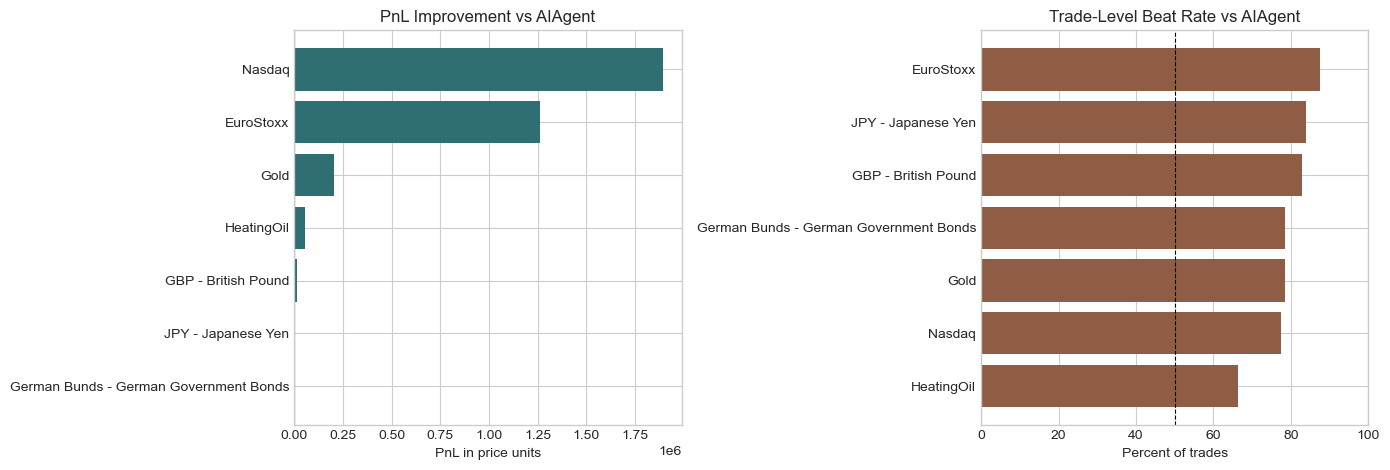

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
plot_df = canonical.sort_values("total_pnl_vs_aiagent", ascending=True)
axes[0].barh(plot_df["exchange"], plot_df["total_pnl_vs_aiagent"], color="#2f6f73")
axes[0].set_title("PnL Improvement vs AIAgent")
axes[0].set_xlabel("PnL in price units")
axes[0].axvline(0, color="black", linewidth=0.8)

beat_df = canonical.sort_values("pct_trades_beat_ai", ascending=True)
axes[1].barh(beat_df["exchange"], beat_df["pct_trades_beat_ai"], color="#8f5d46")
axes[1].set_title("Trade-Level Beat Rate vs AIAgent")
axes[1].set_xlabel("Percent of trades")
axes[1].set_xlim(0, 100)
axes[1].axvline(50, color="black", linewidth=0.8, linestyle="--")

plt.tight_layout()
plt.show()


In [4]:
asset_metrics = pd.read_csv(VALIDATION / "statistical_metrics_by_asset.csv")
portfolio_metrics = pd.read_csv(VALIDATION / "statistical_metrics_portfolio.csv")
bootstrap = pd.read_csv(VALIDATION / "bootstrap_confidence_intervals.csv")

portfolio_display = portfolio_metrics.T.reset_index()
portfolio_display.columns = ["Metric", "Value"]

asset_display = asset_metrics[[
    "asset",
    "n_days",
    "total_pnl_econ",
    "daily_sharpe",
    "daily_sortino",
    "max_drawdown_econ",
    "profit_factor",
    "pnl_to_mdd",
    "positive_day_pct",
]].copy()
asset_display.columns = [
    "Asset",
    "Days",
    "Economic PnL vs AIAgent",
    "Daily Sharpe",
    "Daily Sortino",
    "Max Drawdown",
    "Profit Factor",
    "PnL / MDD",
    "Positive Day %",
]

bootstrap_display = bootstrap[[
    "scope",
    "total_pnl_ci_lower",
    "total_pnl_ci_upper",
    "daily_sharpe_ci_lower",
    "daily_sharpe_ci_upper",
]].copy()
bootstrap_display.columns = [
    "Scope",
    "Total PnL CI Lower",
    "Total PnL CI Upper",
    "Daily Sharpe CI Lower",
    "Daily Sharpe CI Upper",
]

display(Markdown("## Statistical Validation"))
display(Markdown("Daily economic PnL is aggregated by date before computing risk metrics and bootstrap confidence intervals."))
display(Markdown("### Portfolio Metrics"))
display(portfolio_display)
display(Markdown("### Asset Metrics"))
display(asset_display.style.format({
    "Days": "{:,.0f}",
    "Economic PnL vs AIAgent": "{:,.0f}",
    "Daily Sharpe": "{:,.2f}",
    "Daily Sortino": "{:,.2f}",
    "Max Drawdown": "{:,.0f}",
    "Profit Factor": "{:,.2f}",
    "PnL / MDD": "{:,.2f}",
    "Positive Day %": "{:,.1f}%",
}))
display(Markdown("### Bootstrap Confidence Intervals"))
display(bootstrap_display.style.format({
    "Total PnL CI Lower": "{:,.0f}",
    "Total PnL CI Upper": "{:,.0f}",
    "Daily Sharpe CI Lower": "{:,.2f}",
    "Daily Sharpe CI Upper": "{:,.2f}",
}))


## Statistical Validation

Daily economic PnL is aggregated by date before computing risk metrics and bootstrap confidence intervals.

### Portfolio Metrics

,Metric,Value
0,scope,portfolio
1,n_days,443
2,total_pnl_econ,"112,106,896.7617"
3,mean_daily_pnl_econ,"253,062.9724"
4,median_daily_pnl_econ,"98,959.4226"
5,daily_sharpe,6.1293
6,daily_sortino,4.1925
7,max_drawdown_econ,"-5,460,830.4163"
8,profit_factor,16.7454
9,worst_5pct_daily_pnl_econ,"5,398.5158"


### Asset Metrics

,Asset,Days,Economic PnL vs AIAgent,Daily Sharpe,Daily Sortino,Max Drawdown,Profit Factor,PnL / MDD,Positive Day %
0,EuroStoxx,82,"12,613,368",14.50,inf,0,inf,inf,100.0%
1,GBP - British Pound,68,"9,399,333",12.33,inf,"-1,223","7,688.99","7,687.99",98.5%
2,German Bunds - German Government Bonds,63,"3,687,421",8.09,inf,"-367,211",11.04,10.04,98.4%
3,Gold,83,"20,371,180",5.67,3.28,"-5,460,830",4.06,3.73,91.6%
4,HeatingOil,36,"23,110,279",6.44,"1,794.09","-24,730",687.76,934.50,91.7%
5,JPY - Japanese Yen,66,"5,015,637",14.53,inf,0,inf,inf,100.0%
6,Nasdaq,77,"37,909,679",12.05,322.26,"-58,248",380.17,650.83,94.8%


### Bootstrap Confidence Intervals

,Scope,Total PnL CI Lower,Total PnL CI Upper,Daily Sharpe CI Lower,Daily Sharpe CI Upper
0,EuroStoxx,"9,796,488","15,793,350",12.82,16.91
1,GBP - British Pound,"6,762,229","12,506,492",10.15,16.47
2,German Bunds - German Government Bonds,"1,993,719","5,696,730",4.67,16.16
3,Gold,"8,001,261","32,271,516",2.08,10.83
4,HeatingOil,"7,427,241","43,300,415",4.29,9.65
5,JPY - Japanese Yen,"3,762,908","6,428,919",12.48,18.23
6,Nasdaq,"28,243,799","49,881,665",10.04,18.49
7,portfolio,"86,436,848","139,798,175",5.12,7.84


## Robustness Stress Results

The completed stress grid has **126 scenario rows**: 7 assets x 3 tau values x 2 fill policies x 3 remainder policies.

,Asset,Robustness Label,Stress Pass %,Economic PnL,Daily Sharpe,PnL / MDD,Bootstrap PnL Lower,Matching Coverage %,Inside OHLC %,Rationale
0,Nasdaq,fragile win,66.7%,"37,909,679",12.05,650.83,"28,243,799",99.8%,99.8%,"Corrected baseline wins, but one or more robustness, drawdown, bootstrap, or matching thresholds is not fully satisfied."
1,German Bunds - German Government Bonds,fragile win,72.2%,"3,687,421",8.09,10.04,"1,993,719",99.8%,99.8%,"Corrected baseline wins, but one or more robustness, drawdown, bootstrap, or matching thresholds is not fully satisfied."
2,EuroStoxx,robust win,88.9%,"12,613,368",14.50,inf,"9,796,488",98.6%,98.6%,"Positive corrected PnL, positive risk metrics, positive bootstrap lower bound, and stress pass rate >= 75%."
3,Gold,fragile win,16.7%,"20,371,180",5.67,3.73,"8,001,261",99.8%,99.1%,"Corrected baseline wins, but one or more robustness, drawdown, bootstrap, or matching thresholds is not fully satisfied."
4,HeatingOil,fragile win,88.9%,"23,110,279",6.44,934.50,"7,427,241",94.8%,86.9%,"Corrected baseline wins, but one or more robustness, drawdown, bootstrap, or matching thresholds is not fully satisfied."
5,JPY - Japanese Yen,fragile win,66.7%,"5,015,637",14.53,inf,"3,762,908",99.9%,99.9%,"Corrected baseline wins, but one or more robustness, drawdown, bootstrap, or matching thresholds is not fully satisfied."
6,GBP - British Pound,fragile win,66.7%,"9,399,333",12.33,"7,687.99","6,762,229",100.0%,100.0%,"Corrected baseline wins, but one or more robustness, drawdown, bootstrap, or matching thresholds is not fully satisfied."


### Scenario Coverage

,asset,Scenario Rows,Stress Pass %
0,EuroStoxx,18,88.9%
4,HeatingOil,18,88.9%
2,German Bunds - German Government Bonds,18,72.2%
1,GBP - British Pound,18,66.7%
5,JPY - Japanese Yen,18,66.7%
6,Nasdaq,18,66.7%
3,Gold,18,16.7%


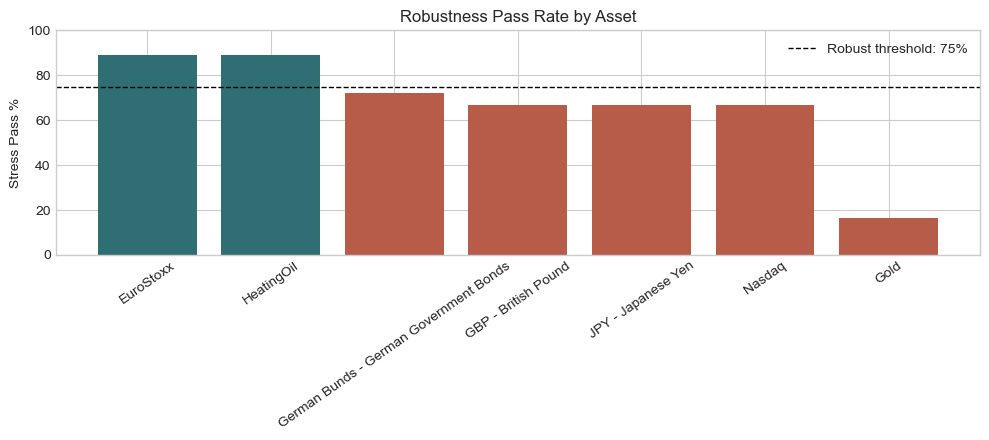

In [5]:
stress = pd.read_csv(VALIDATION / "robustness_stress_results.csv")
labels = pd.read_csv(VALIDATION / "robustness_asset_labels.csv")

label_display = labels[[
    "asset",
    "robustness_label",
    "stress_pass_rate_pct",
    "total_pnl_econ",
    "daily_sharpe",
    "pnl_to_mdd",
    "total_pnl_ci_lower",
    "matching_coverage_pct",
    "inside_ohlc_pct",
    "rationale",
]].copy()
label_display.columns = [
    "Asset",
    "Robustness Label",
    "Stress Pass %",
    "Economic PnL",
    "Daily Sharpe",
    "PnL / MDD",
    "Bootstrap PnL Lower",
    "Matching Coverage %",
    "Inside OHLC %",
    "Rationale",
]

scenario_count = stress.groupby("asset").size().rename("Scenario Rows").reset_index()
pass_rate = stress.groupby("asset")["stress_pass"].mean().mul(100).rename("Stress Pass %").reset_index()
scenario_summary = scenario_count.merge(pass_rate, on="asset").sort_values("Stress Pass %", ascending=False)

display(Markdown("## Robustness Stress Results"))
display(Markdown(f"The completed stress grid has **{len(stress):,} scenario rows**: 7 assets x 3 tau values x 2 fill policies x 3 remainder policies."))
display(label_display.style.format({
    "Stress Pass %": "{:,.1f}%",
    "Economic PnL": "{:,.0f}",
    "Daily Sharpe": "{:,.2f}",
    "PnL / MDD": "{:,.2f}",
    "Bootstrap PnL Lower": "{:,.0f}",
    "Matching Coverage %": "{:,.1f}%",
    "Inside OHLC %": "{:,.1f}%",
}))

display(Markdown("### Scenario Coverage"))
display(scenario_summary.style.format({"Stress Pass %": "{:,.1f}%", "Scenario Rows": "{:,.0f}"}))

fig, ax = plt.subplots(figsize=(10, 4.5))
colors = ["#2f6f73" if v >= 75 else "#b85c4a" for v in scenario_summary["Stress Pass %"]]
ax.bar(scenario_summary["asset"], scenario_summary["Stress Pass %"], color=colors)
ax.axhline(75, color="black", linestyle="--", linewidth=1, label="Robust threshold: 75%")
ax.set_ylabel("Stress Pass %")
ax.set_ylim(0, 100)
ax.set_title("Robustness Pass Rate by Asset")
ax.tick_params(axis="x", rotation=35)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


## Attribution by Asset

This table decomposes the strategy improvement versus AIAgent and benchmark by asset.

,Asset,Trades,Strategy vs AIAgent Econ,Strategy vs Benchmark Econ,Benchmark vs AIAgent Econ,Mean Improvement Ticks
6,Nasdaq,"18,932","37,909,679","35,999,514","1,910,165",64.89
4,HeatingOil,"6,314","23,110,279","2,085,436","21,024,843",260.46
3,Gold,"19,711","20,371,180","28,123,950","-7,752,770",33.97
0,EuroStoxx,"17,870","12,613,368","11,277,263","1,336,105",49.92
1,GBP - British Pound,"13,745","9,399,333","9,438,646","-39,313",18.01
5,JPY - Japanese Yen,"12,662","5,015,637","5,071,699","-56,062",16.81
2,German Bunds - German Government Bonds,"12,992","3,687,421","2,888,881","798,540",6.58


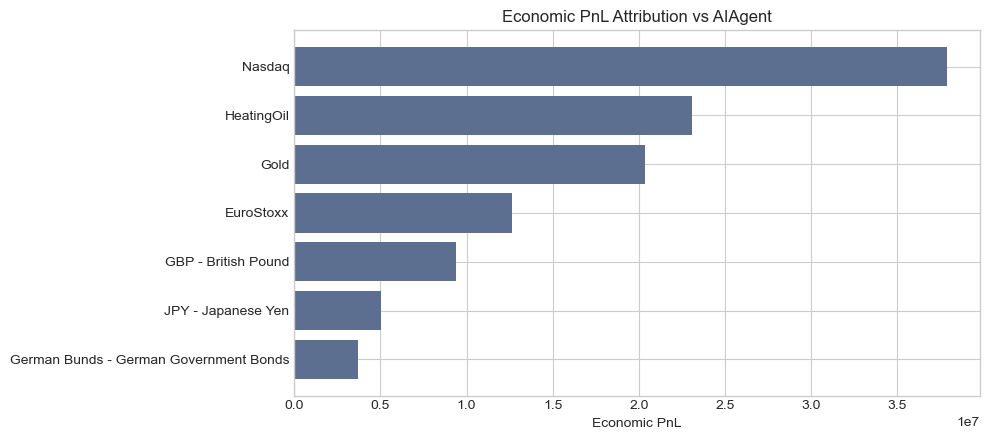

In [6]:
attribution = pd.read_csv(VALIDATION / "attribution_by_asset.csv")
attr_display = attribution.sort_values("strategy_vs_agent_econ", ascending=False).copy()
attr_display.columns = [
    "Asset",
    "Trades",
    "Strategy vs AIAgent Econ",
    "Strategy vs Benchmark Econ",
    "Benchmark vs AIAgent Econ",
    "Mean Improvement Ticks",
]

display(Markdown("## Attribution by Asset"))
display(Markdown("This table decomposes the strategy improvement versus AIAgent and benchmark by asset."))
display(attr_display.style.format({
    "Trades": "{:,.0f}",
    "Strategy vs AIAgent Econ": "{:,.0f}",
    "Strategy vs Benchmark Econ": "{:,.0f}",
    "Benchmark vs AIAgent Econ": "{:,.0f}",
    "Mean Improvement Ticks": "{:,.2f}",
}))

fig, ax = plt.subplots(figsize=(10, 4.5))
plot_attr = attr_display.sort_values("Strategy vs AIAgent Econ", ascending=True)
ax.barh(plot_attr["Asset"], plot_attr["Strategy vs AIAgent Econ"], color="#5c6f91")
ax.set_title("Economic PnL Attribution vs AIAgent")
ax.set_xlabel("Economic PnL")
plt.tight_layout()
plt.show()


## Report Charts

### All-assets summary across the final strategy package.

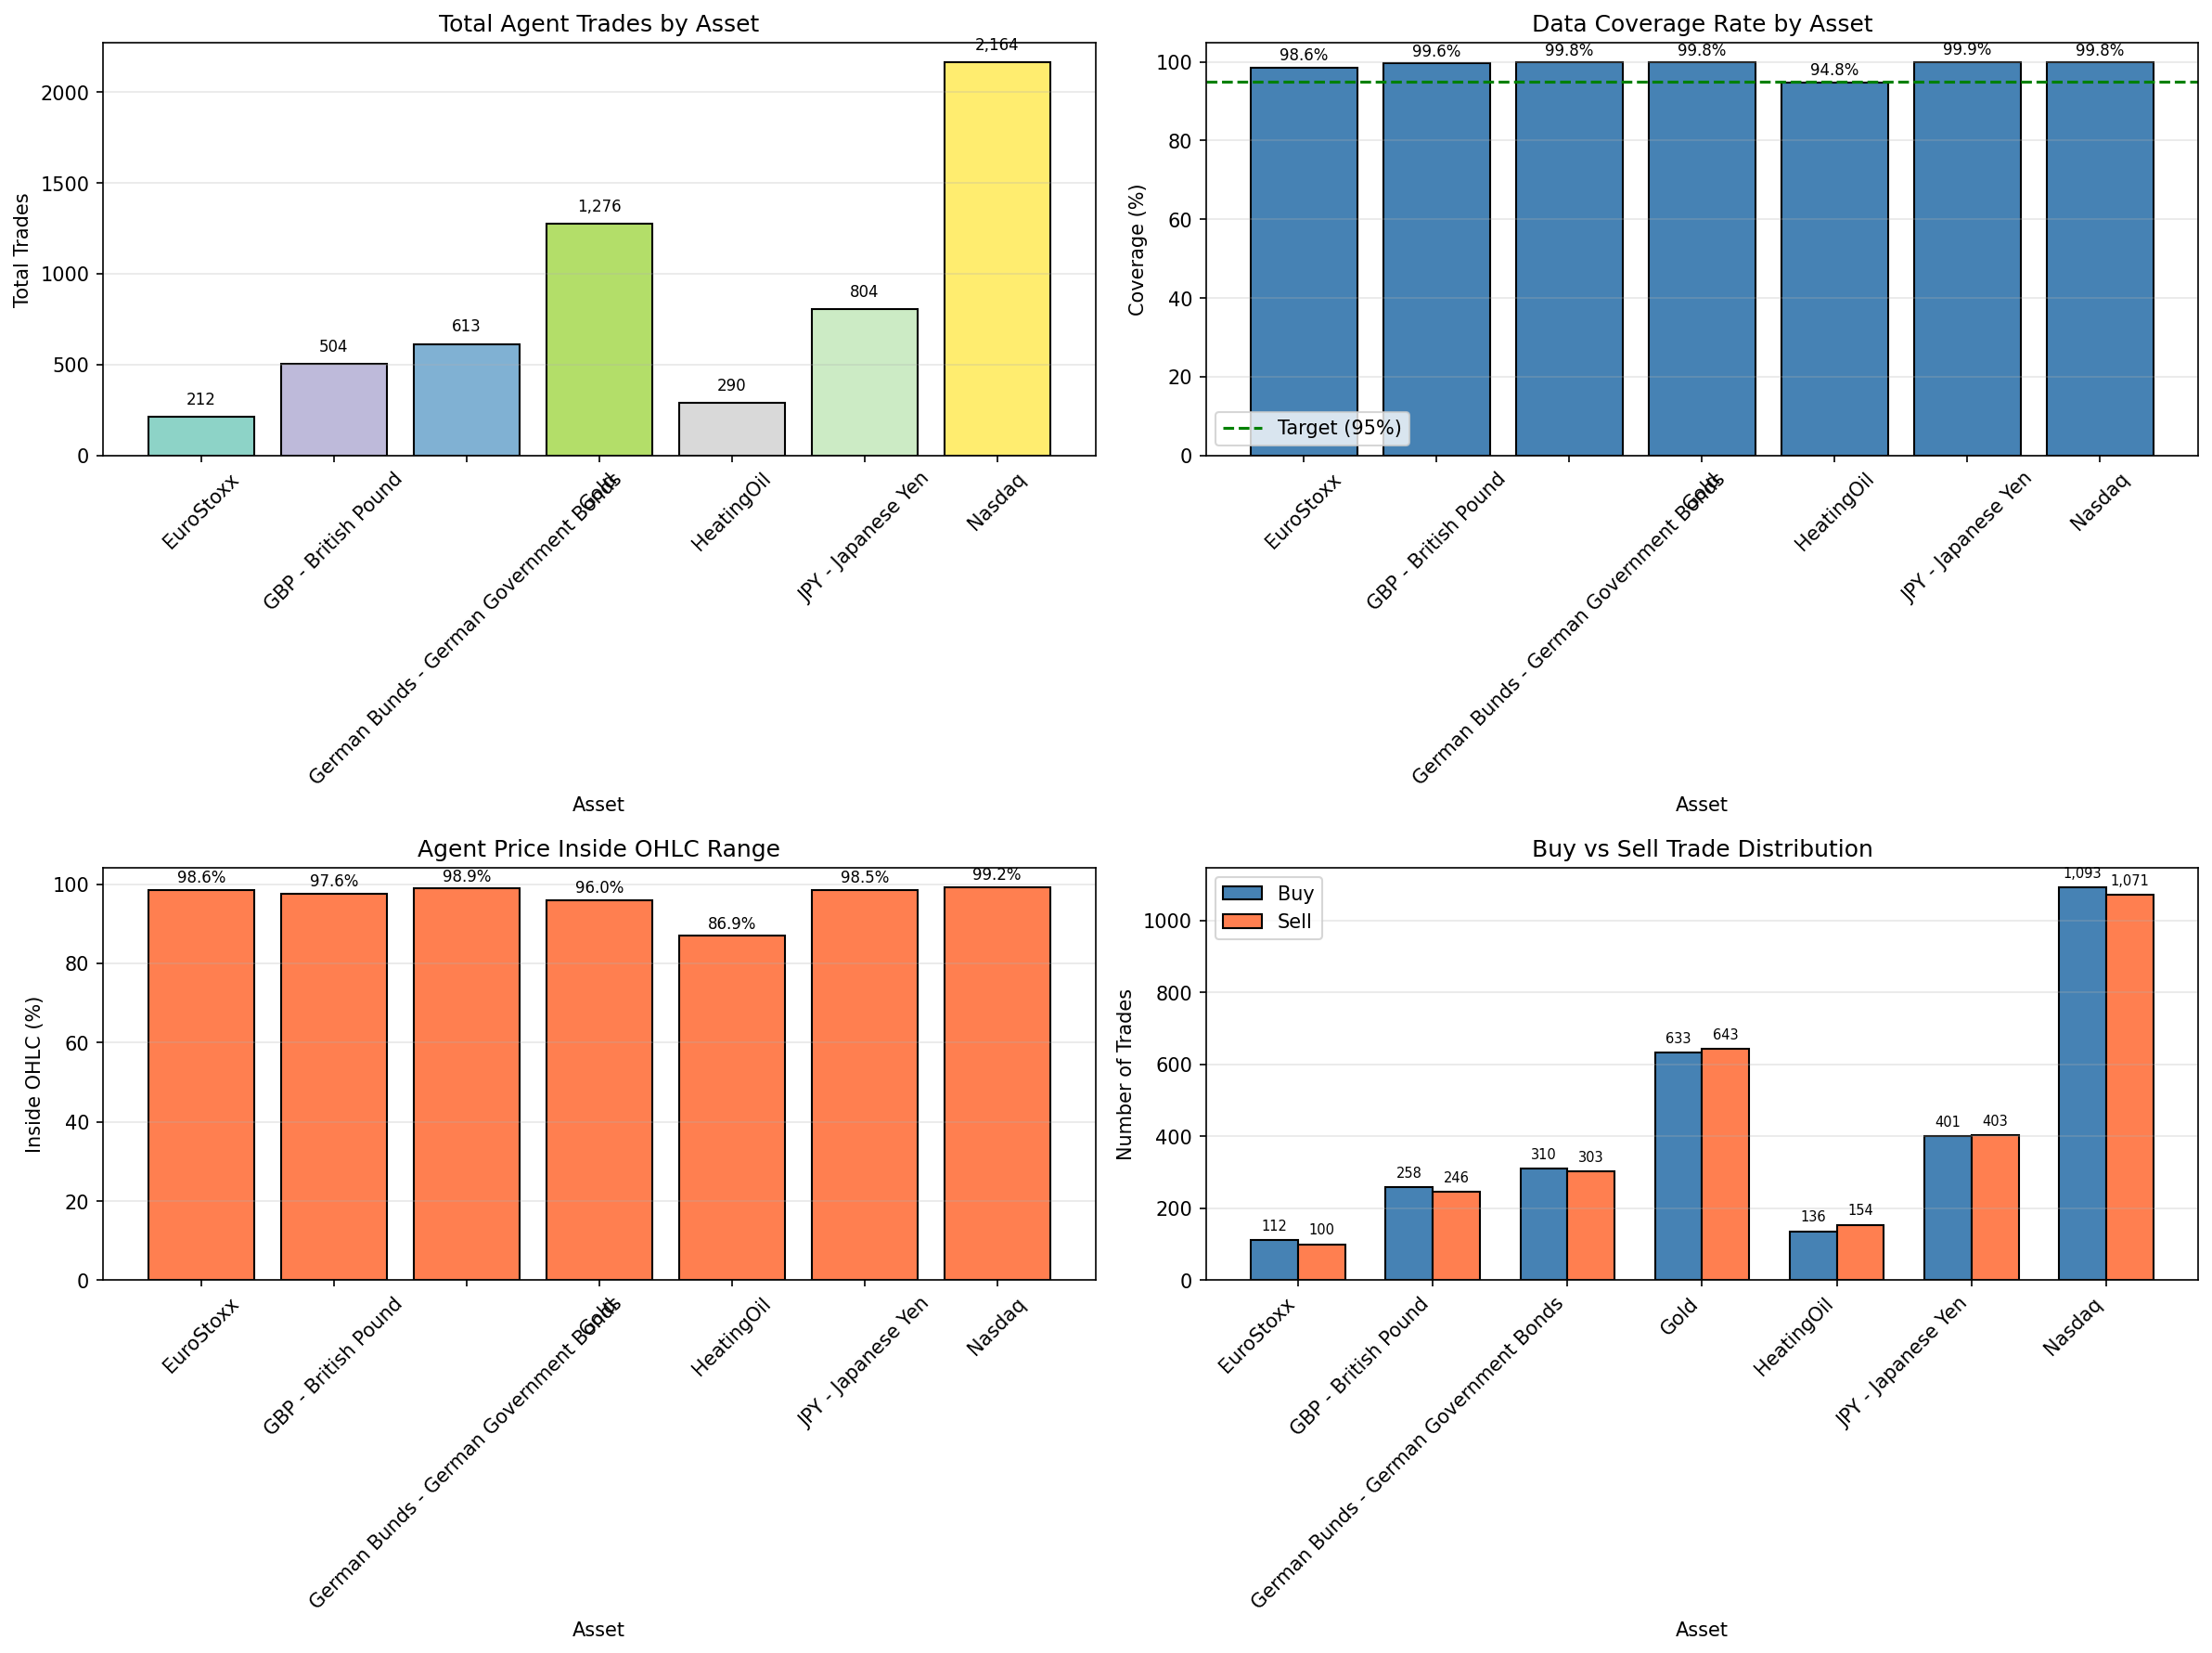

### Backtest comparison chart.

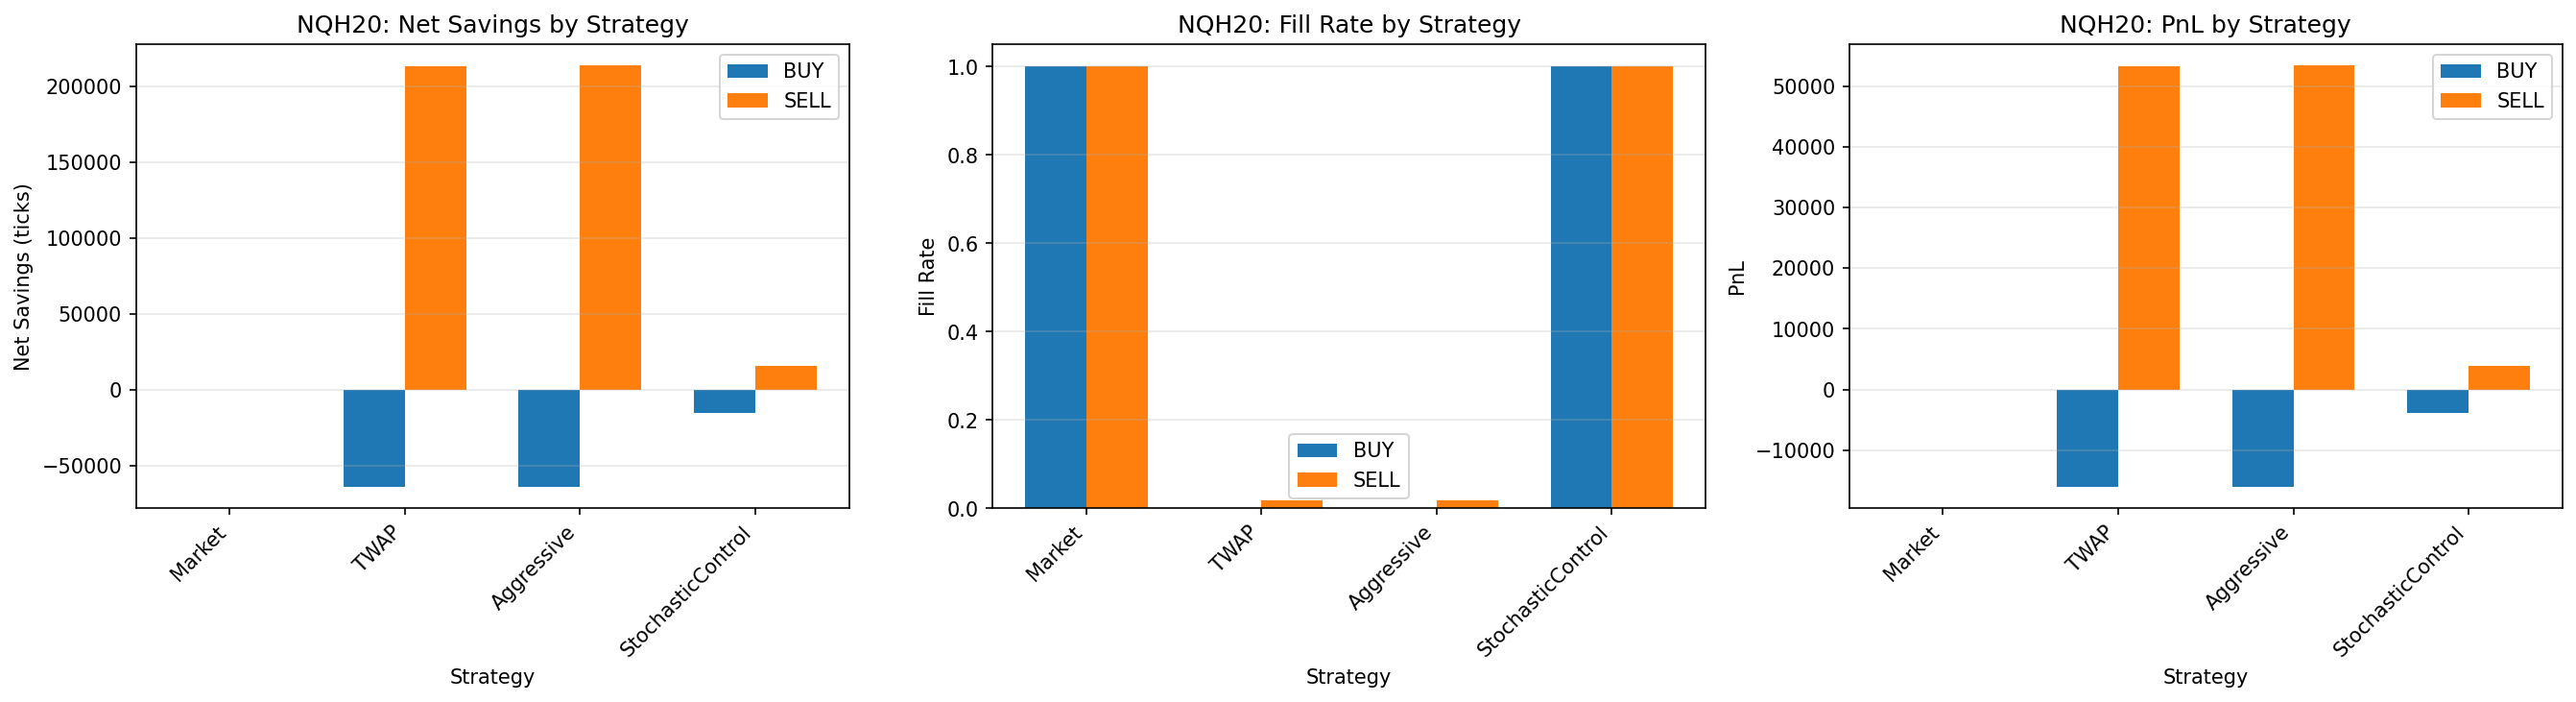

### Nasdaq empirical distribution and fill-probability visualization.

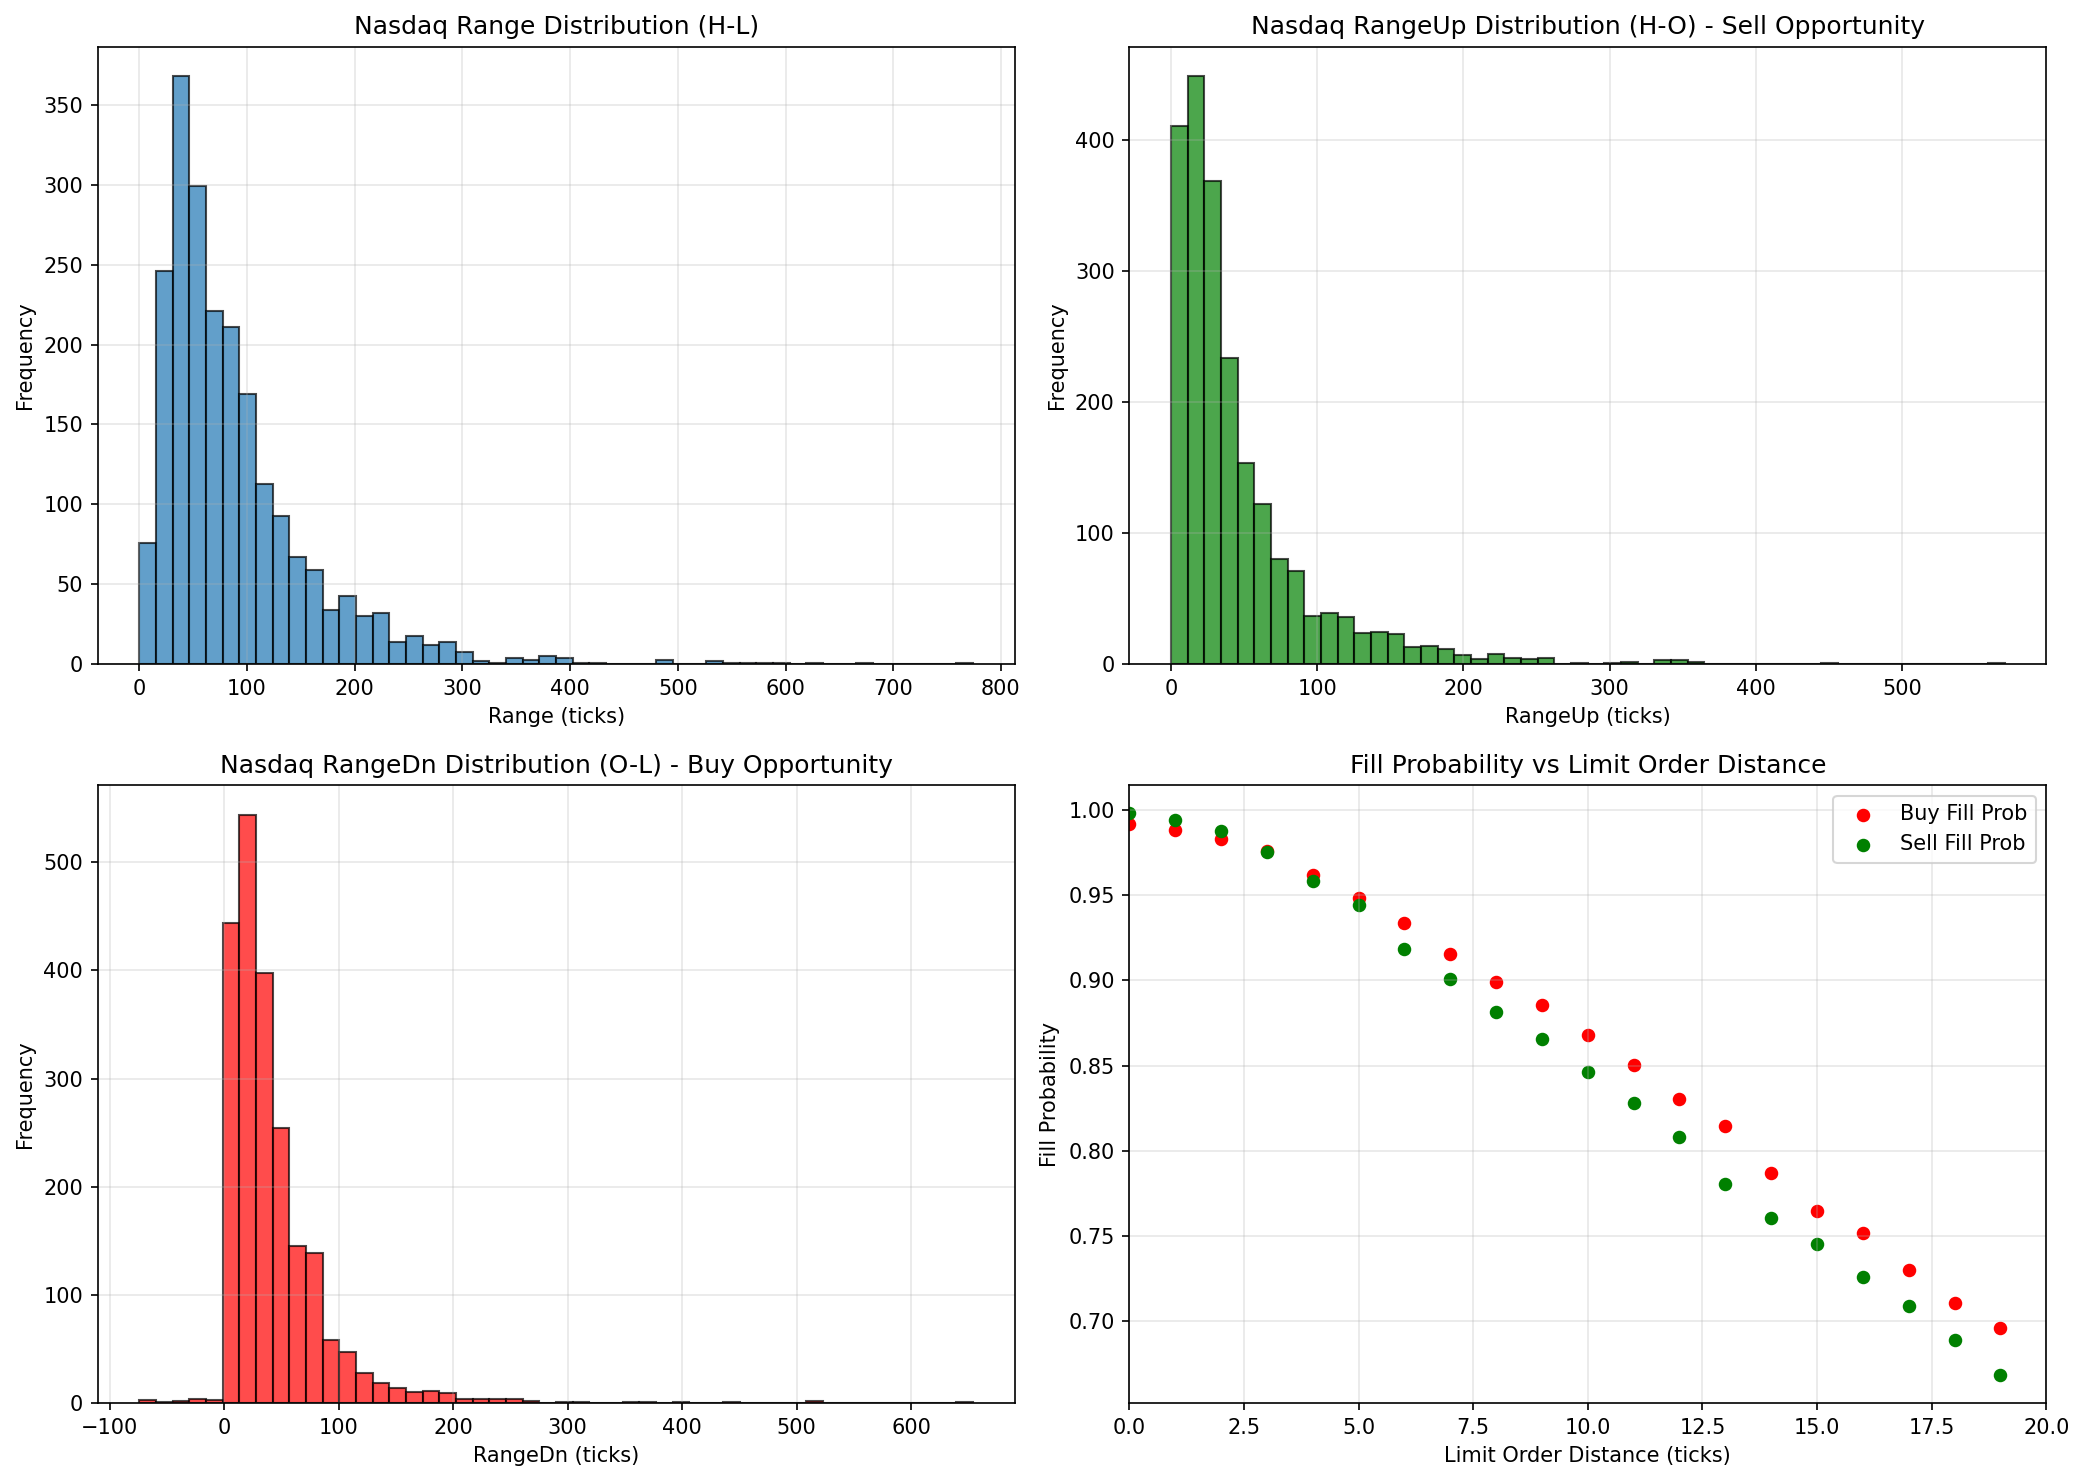

### State-conditioned ePDF behavior for Nasdaq.

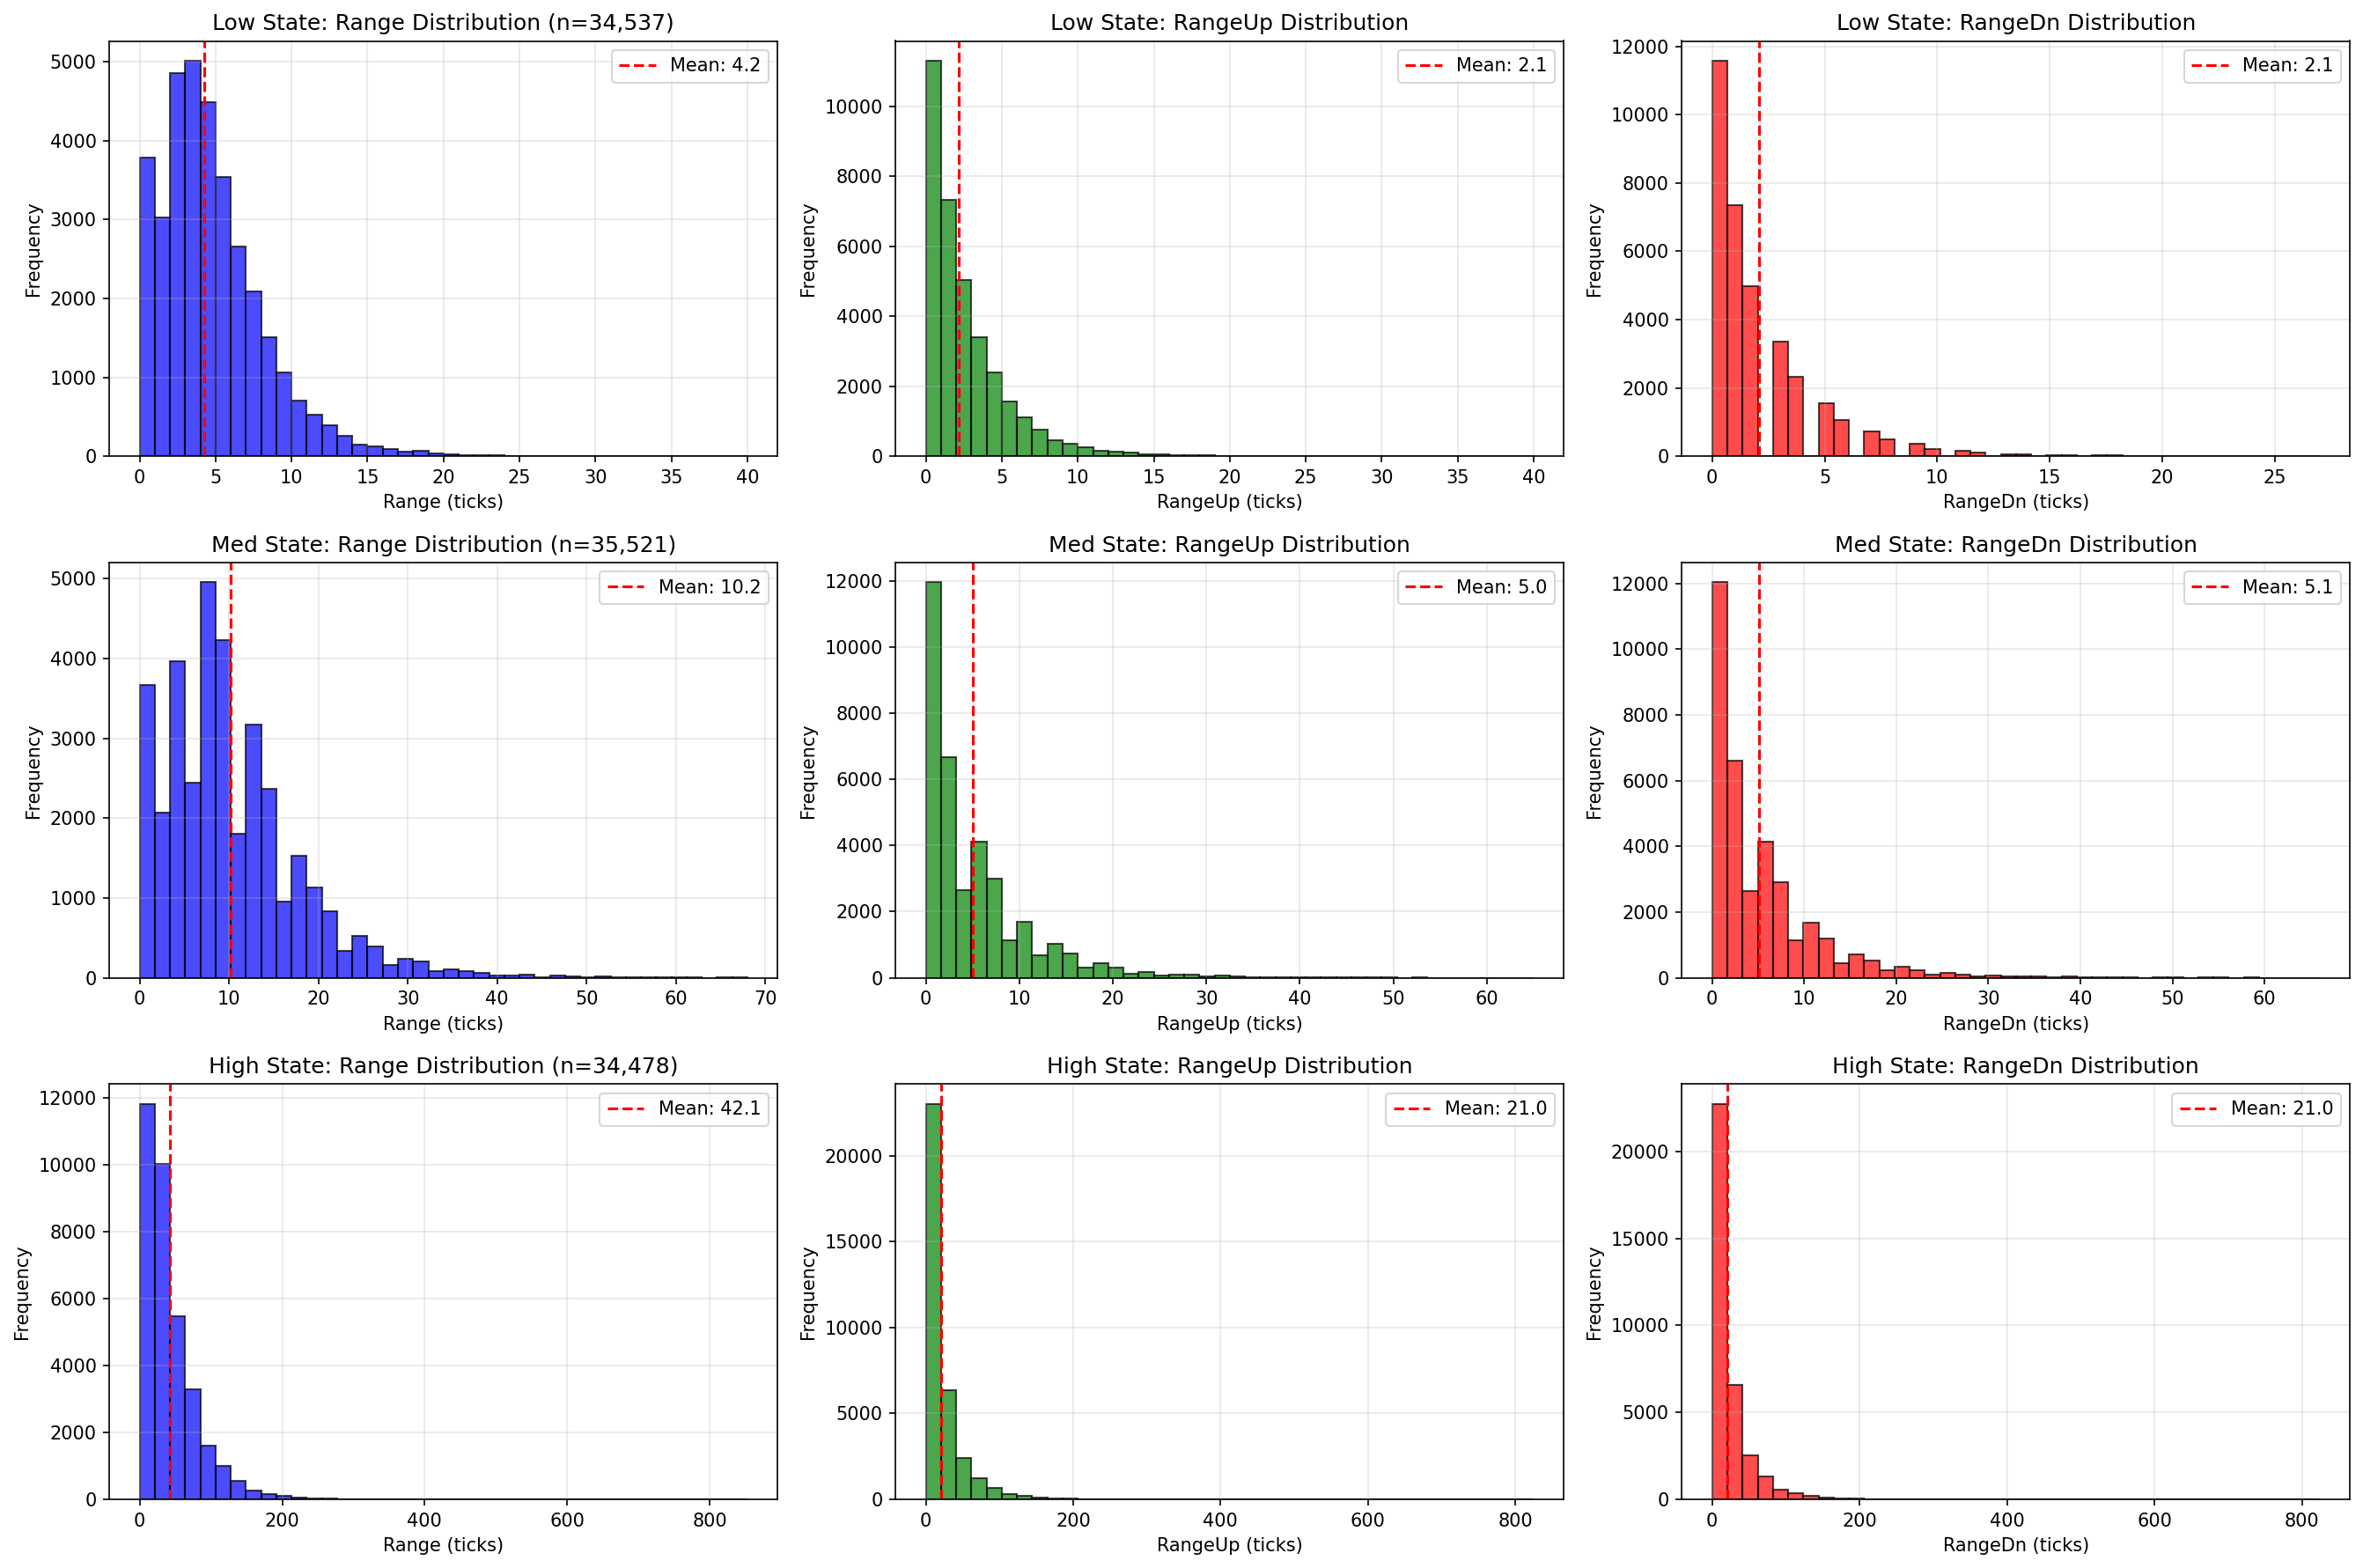

### Nasdaq state distribution.

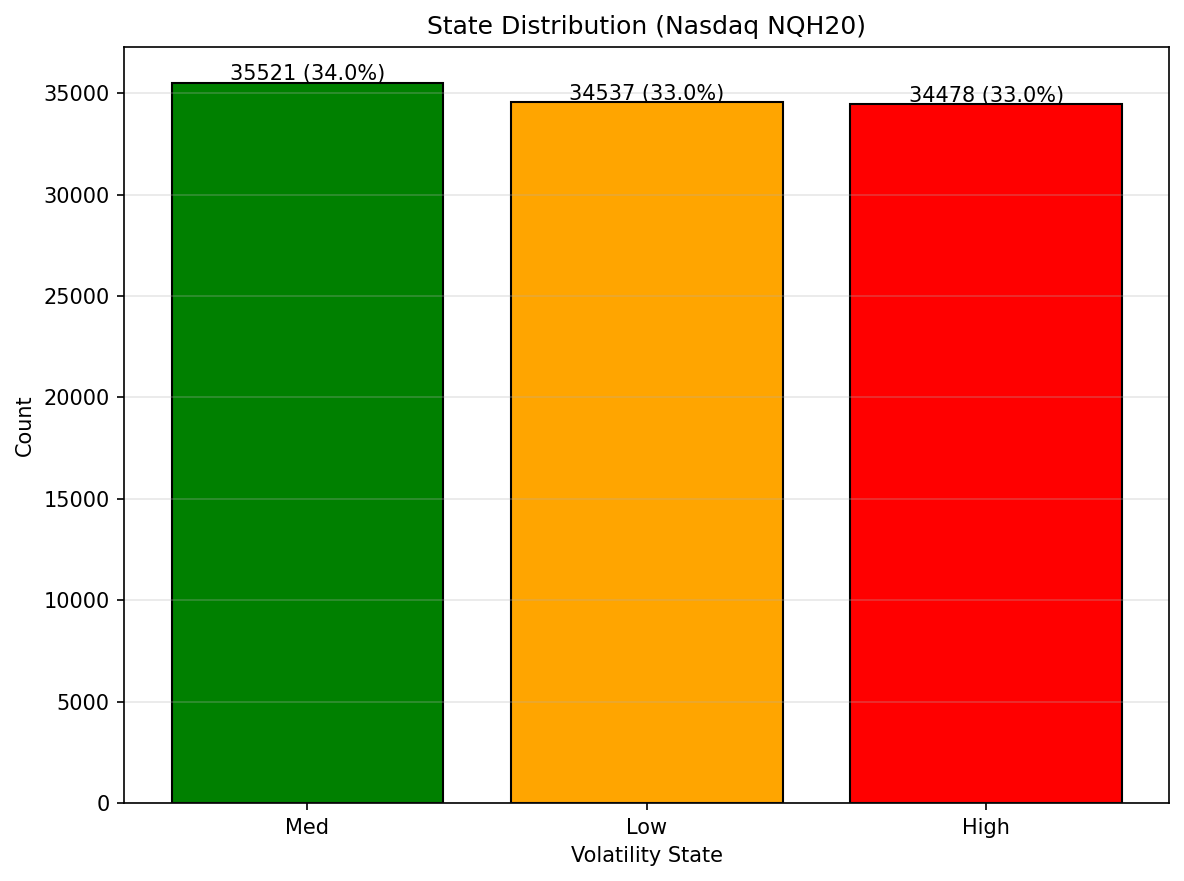

In [7]:
chart_specs = [
    ("results/all_assets_summary.png", "All-assets summary across the final strategy package."),
    ("results/backtest_comparison_chart.png", "Backtest comparison chart."),
    ("results/epdf_histograms_nasdaq.png", "Nasdaq empirical distribution and fill-probability visualization."),
    ("results/state_conditioned_epdf_nasdaq.png", "State-conditioned ePDF behavior for Nasdaq."),
    ("results/state_distribution_nasdaq.png", "Nasdaq state distribution."),
]

display(Markdown("## Report Charts"))
for rel_path, caption in chart_specs:
    path = ROOT / rel_path
    if path.exists():
        display(Markdown(f"### {caption}"))
        display(Image(filename=str(path)))
    else:
        display(Markdown(f"Missing chart: `{rel_path}`"))


## Parameter Scenario UI

The default output below is saved in the submitted notebook. If `ipywidgets` is installed, the controls remain interactive in Jupyter.

### Selected Scenario: Nasdaq | tau=45 | fill=default | remainder=best_or_benchmark
Stress status: **PASS**. Asset-level robustness label: **fragile win**. Selected metric `total_pnl_vs_aiagent_econ` = **37,909,679.0017**.

,asset,tau,fill_policy,remainder_policy,n_trades,total_pnl_vs_aiagent_econ,daily_sharpe,pct_trades_beat_ai,mean_trade_improvement_ticks,max_drawdown_econ,stress_pass
120,Nasdaq,45,default,best_or_benchmark,"18,932","37,909,679",12.05,77.6%,64.89,"-58,248",True


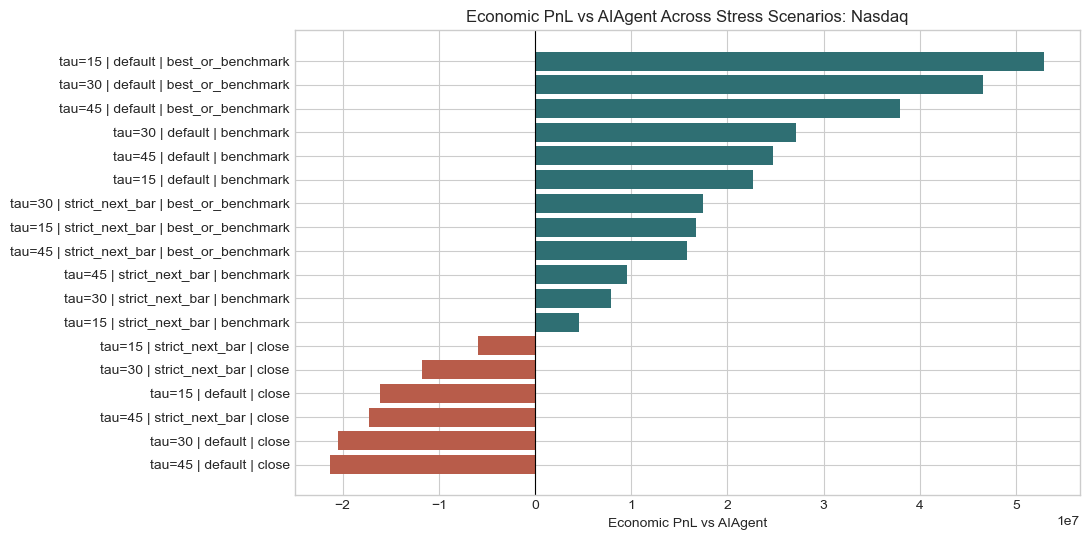

Output()

In [8]:
metric_options = {
    "Economic PnL vs AIAgent": "total_pnl_vs_aiagent_econ",
    "Daily Sharpe": "daily_sharpe",
    "Beat AIAgent %": "pct_trades_beat_ai",
    "Mean Improvement Ticks": "mean_trade_improvement_ticks",
    "Max Drawdown Econ": "max_drawdown_econ",
}

def scenario_table(asset: str, tau: int, fill_policy: str, remainder_policy: str) -> pd.DataFrame:
    mask = (
        (stress["asset"] == asset)
        & (stress["tau"] == tau)
        & (stress["fill_policy"] == fill_policy)
        & (stress["remainder_policy"] == remainder_policy)
    )
    return stress.loc[mask].copy()


def render_scenario(asset="Nasdaq", tau=45, fill_policy="default", remainder_policy="best_or_benchmark", metric_label="Economic PnL vs AIAgent"):
    metric = metric_options[metric_label]
    row = scenario_table(asset, tau, fill_policy, remainder_policy)
    if row.empty:
        display(Markdown("No scenario row matched the selected parameters."))
        return

    selected = row.iloc[0]
    label_row = labels.loc[labels["asset"] == asset]
    robustness_label = label_row["robustness_label"].iloc[0] if not label_row.empty else "unknown"
    pass_text = "PASS" if bool(selected["stress_pass"]) else "FAIL"

    display(Markdown(
        f"### Selected Scenario: {asset} | tau={tau} | fill={fill_policy} | remainder={remainder_policy}\n"
        f"Stress status: **{pass_text}**. Asset-level robustness label: **{robustness_label}**. "
        f"Selected metric `{metric}` = **{selected[metric]:,.4f}**."
    ))

    detail_cols = [
        "asset", "tau", "fill_policy", "remainder_policy", "n_trades",
        "total_pnl_vs_aiagent_econ", "daily_sharpe", "pct_trades_beat_ai",
        "mean_trade_improvement_ticks", "max_drawdown_econ", "stress_pass",
    ]
    display(row[detail_cols].style.format({
        "n_trades": "{:,.0f}",
        "total_pnl_vs_aiagent_econ": "{:,.0f}",
        "daily_sharpe": "{:,.2f}",
        "pct_trades_beat_ai": "{:,.1f}%",
        "mean_trade_improvement_ticks": "{:,.2f}",
        "max_drawdown_econ": "{:,.0f}",
    }))

    asset_scenarios = stress.loc[stress["asset"] == asset].copy()
    asset_scenarios["Scenario"] = (
        "tau=" + asset_scenarios["tau"].astype(str)
        + " | " + asset_scenarios["fill_policy"].astype(str)
        + " | " + asset_scenarios["remainder_policy"].astype(str)
    )
    asset_scenarios = asset_scenarios.sort_values(metric, ascending=True)

    fig, ax = plt.subplots(figsize=(11, 5.5))
    bar_colors = ["#2f6f73" if ok else "#b85c4a" for ok in asset_scenarios["stress_pass"]]
    ax.barh(asset_scenarios["Scenario"], asset_scenarios[metric], color=bar_colors)
    ax.set_title(f"{metric_label} Across Stress Scenarios: {asset}")
    ax.set_xlabel(metric_label)
    ax.axvline(0, color="black", linewidth=0.8)
    plt.tight_layout()
    plt.show()


display(Markdown("## Parameter Scenario UI"))
display(Markdown("The default output below is saved in the submitted notebook. If `ipywidgets` is installed, the controls remain interactive in Jupyter."))
render_scenario()

try:
    import ipywidgets as widgets
    from IPython.display import clear_output

    asset_widget = widgets.Dropdown(options=sorted(stress["asset"].unique()), value="Nasdaq", description="Asset")
    tau_widget = widgets.Dropdown(options=sorted(stress["tau"].unique()), value=45, description="Tau")
    fill_widget = widgets.Dropdown(options=sorted(stress["fill_policy"].unique()), value="default", description="Fill")
    remainder_widget = widgets.Dropdown(options=sorted(stress["remainder_policy"].unique()), value="best_or_benchmark", description="Remainder")
    metric_widget = widgets.Dropdown(options=list(metric_options.keys()), value="Economic PnL vs AIAgent", description="Metric")
    out = widgets.Output()

    def update_ui(*_):
        with out:
            clear_output(wait=True)
            render_scenario(
                asset_widget.value,
                tau_widget.value,
                fill_widget.value,
                remainder_widget.value,
                metric_widget.value,
            )

    for widget in [asset_widget, tau_widget, fill_widget, remainder_widget, metric_widget]:
        widget.observe(update_ui, names="value")

    controls = widgets.VBox([
        widgets.HBox([asset_widget, tau_widget]),
        widgets.HBox([fill_widget, remainder_widget]),
        metric_widget,
    ])
    display(controls, out)
    update_ui()
except Exception as exc:
    display(Markdown(
        "Interactive widgets are not available in this kernel. "
        "Install the project requirements with `pip install -r requirements.txt` and reopen the notebook for dropdown controls. "
        f"Fallback reason: `{type(exc).__name__}: {exc}`"
    ))


## Optional Local Rerun Commands

The notebook above loads committed artifacts so it opens quickly with results already
visible. To regenerate the reported evidence locally, place the licensed vendor data
under `ORDER_DATA_ROOT` (see `DATA_POLICY.md`) and run, from the repository root:

```bash
python -B validation_framework.py all
python -B validation_framework.py stats --bootstrap-days 2000
python -B validation_framework.py report
```

The lightweight verification commands are:

```bash
python -B run_tests_simple.py
python -B test_validation_framework.py
python -B -m py_compile validation_framework.py
git diff --check
```

The original full-pipeline driver `order_execution_project.py` is joint work and is not
distributed here, so `run-robustness --grid defensible` is the one command that cannot
be reproduced from this repository; its output is committed under
`validation_outputs/robustness_stress_results.csv`. See `EXCLUSIONS.md`.


## Limitations and Final Claim

The corrected tau-45 raw-tick run beats AIAgent overall on all 7 tested futures assets. Robustness claims are intentionally conservative and should be read from `validation_outputs/robustness_asset_labels.csv`: the baseline is strong, while several assets remain labeled fragile under the stress grid.

This is an academic backtest and validation package, not a production trading system or live trading recommendation.
